In [1]:
import sys
sys.path.append("..")
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data import load_dataset, split_data
from src.models import *
from src.evaluate import *
from src.explain import oof_shap

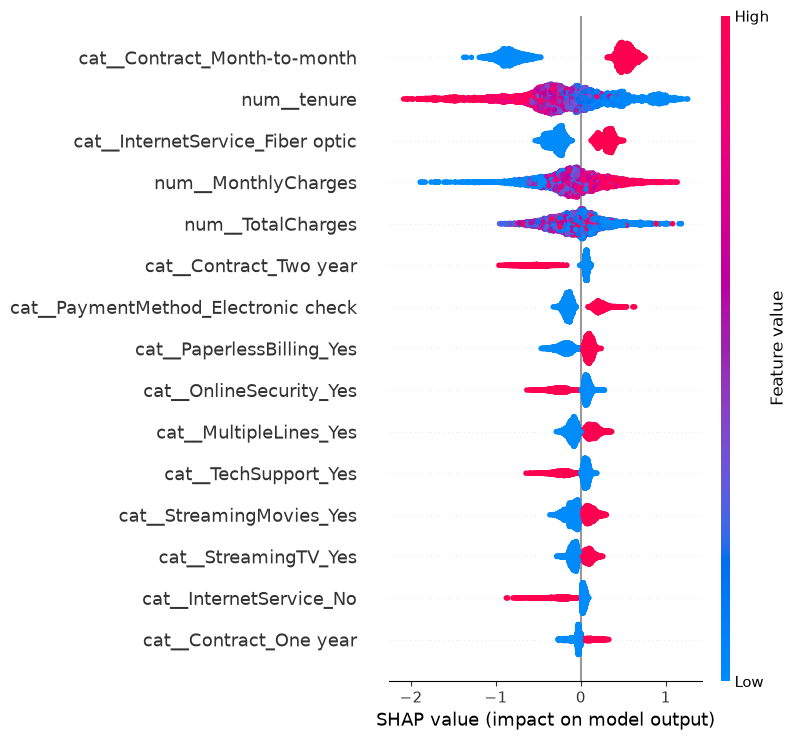

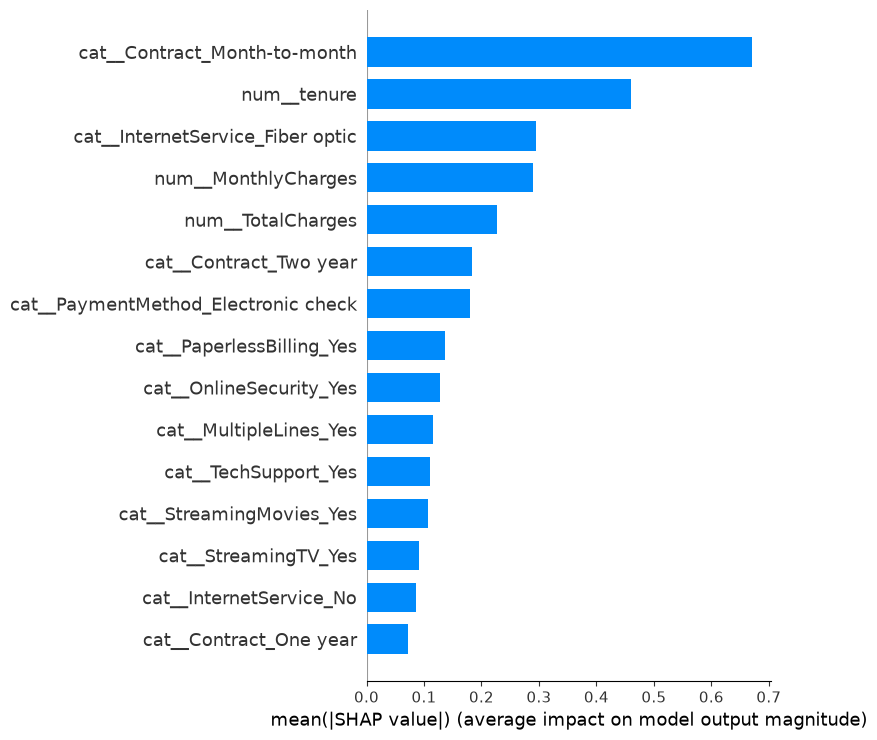

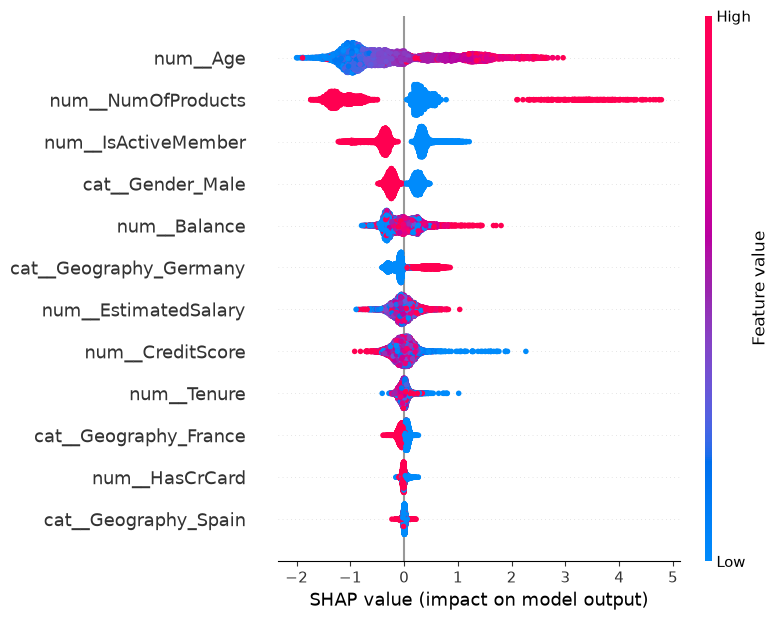

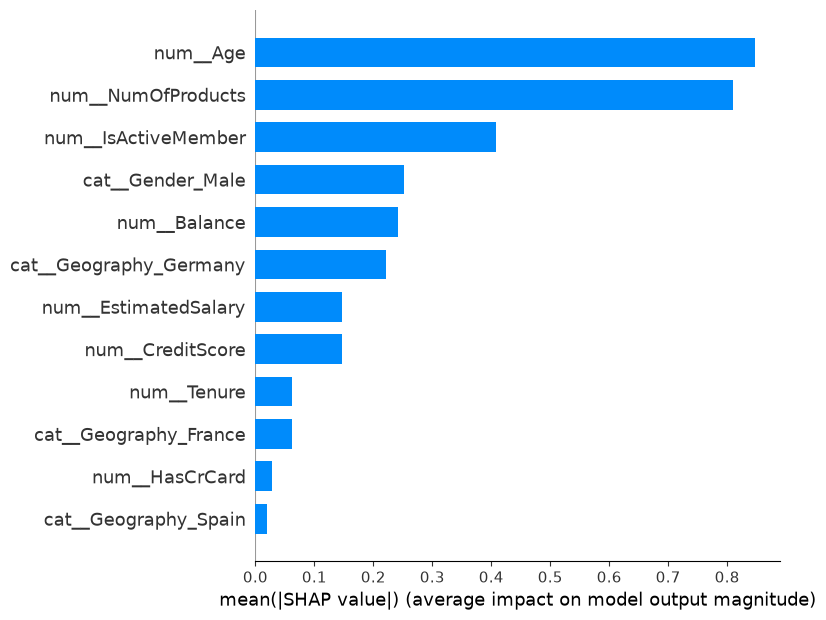

In [2]:
import shap
for name in ["telco", "bank"]:
    X_train, X_test, y_train, y_test = split_data(load_dataset(name))
    sv, Xt = oof_shap(make_xgb(X_train), X_train, y_train, CV)
    np.save(f"../results/shap_{name}.npy", sv)
    Xt.to_csv(f"../results/shap_features_{name}.csv", index=False)

    shap.summary_plot(sv, Xt, show=False, max_display=15)
    plt.savefig(f"../figures/shap_summary_{name}.png", bbox_inches="tight"); plt.show()
    shap.summary_plot(sv, Xt, plot_type="bar", show=False, max_display=15)
    plt.savefig(f"../figures/shap_bar_{name}.png", bbox_inches="tight"); plt.show()